## Setup & Data Load

In [15]:
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from Protein_Sequence_Based_Prediction_of_Folding_Kinetics import(
    fetch_dataset,
    validate_dataset
)

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]

In [16]:
# -------------------------------
# Import data
# -------------------------------
data = fetch_dataset("analysis_dataset.sql")

# Change 'NA' values back to pandas null
data = data.replace('NA', pd.NA)

report = validate_dataset(data)

# Ensure the one-to-one relationship established for measurement_id
assert data["measurement_id"].is_unique
assert len(data) == data["measurement_id"].nunique()

report

{'rows': 1381,
 'unique_measurements': 1381,
 'duplicate_measurement_ids': 0,
 'unique_proteins': 61,
 'unique_mutations': 1338,
 'missing_target': 257,
 'missing_reference_context': 74,
 'missing_mutation_context': 135}

## General data exploration

In [17]:
# Explore data columns with most missing data
data.isna().mean().sort_values(ascending=False)

beta_t                 0.960174
additives              0.755250
ec_number              0.712527
ddgkin_h2o             0.445329
dg_kin_h2o             0.380159
dln_ku_h2o             0.292542
dln_kf_h2o             0.244750
ln_ku_h2o              0.230992
mf                     0.221579
ln_kf_h2o              0.186097
mu                     0.149891
reversibility          0.108617
mutation_context       0.097755
cath                   0.083997
secondary_structure    0.063722
reference_context      0.053584
pfam                   0.029689
authors                0.018103
buffer_conc            0.001448
state                  0.001448
buffer_name            0.001448
kinetic_measurement    0.000724
variable_id            0.000000
experiment_id          0.000000
measurement_id         0.000000
uniprot_id             0.000000
protein_id             0.000000
mutation_uniprot       0.000000
mutated_chain          0.000000
mutation_id            0.000000
protein_length         0.000000
protein_

In [18]:
data[data['reference_context'].isna()]['protein_name'].value_counts().sort_values(ascending = False)

protein_name
Rd-apocyt b562 (de novo)                       41
CBP, KIX domain                                12
PSD1(D27E/Y28K/E43W)                            9
Nucleophosmin, Cter-NPM1 domain                 6
FADD-DD Fas-associated death domain protein     4
Fyn SH3                                         1
Grb2-SH3                                        1
Name: count, dtype: int64

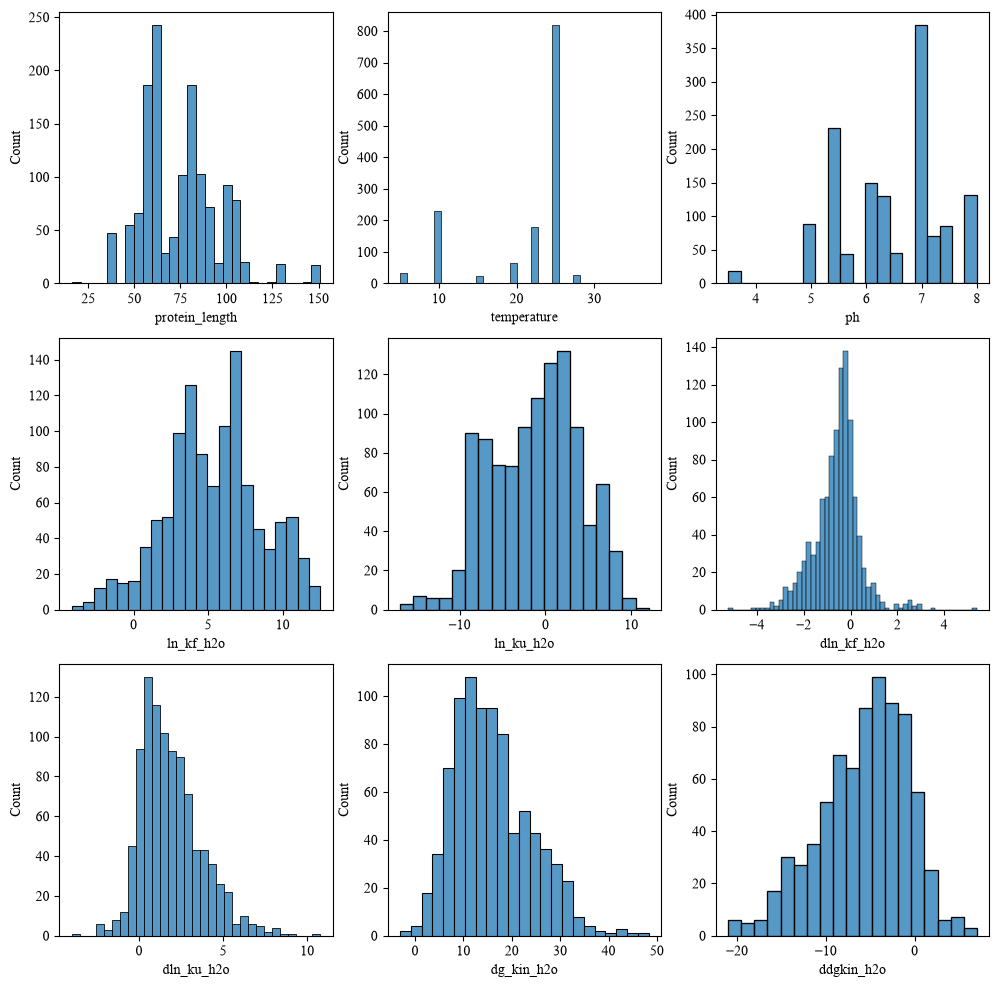

In [ ]:
# Plot distribution of numeric columns (Histogram)
column_names = ['protein_length', 'temperature', 'ph', 'ln_kf_h2o', 'ln_ku_h2o', 'dln_kf_h2o', 'dln_ku_h2o', 'dg_kin_h2o', 'ddgkin_h2o']
data_numeric = data[column_names]

fig, axes = plt.subplots(3, 3, figsize = (12, 12))

for i, ax in enumerate(fig.axes):
    sns.histplot(data = data, x = column_names[i], ax = ax)
    #ax.set_title(column_names[i].title())
plt.show()

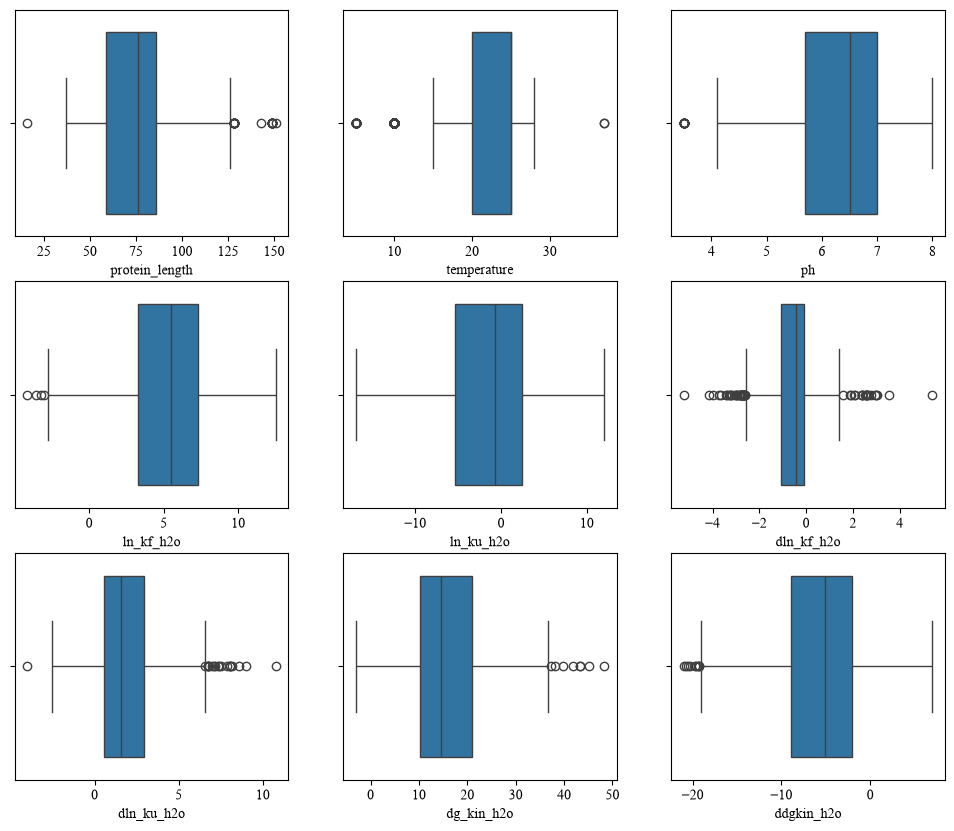

In [27]:
# Plot distribution of numeric columns (Boxplot)
fig, axes = plt.subplots(3, 3, figsize = (12, 10))

for i, ax in enumerate(fig.axes):
    sns.boxplot(data = data, x = column_names[i], ax = ax)
    #ax.set_title(column_names[i].title())
plt.show()

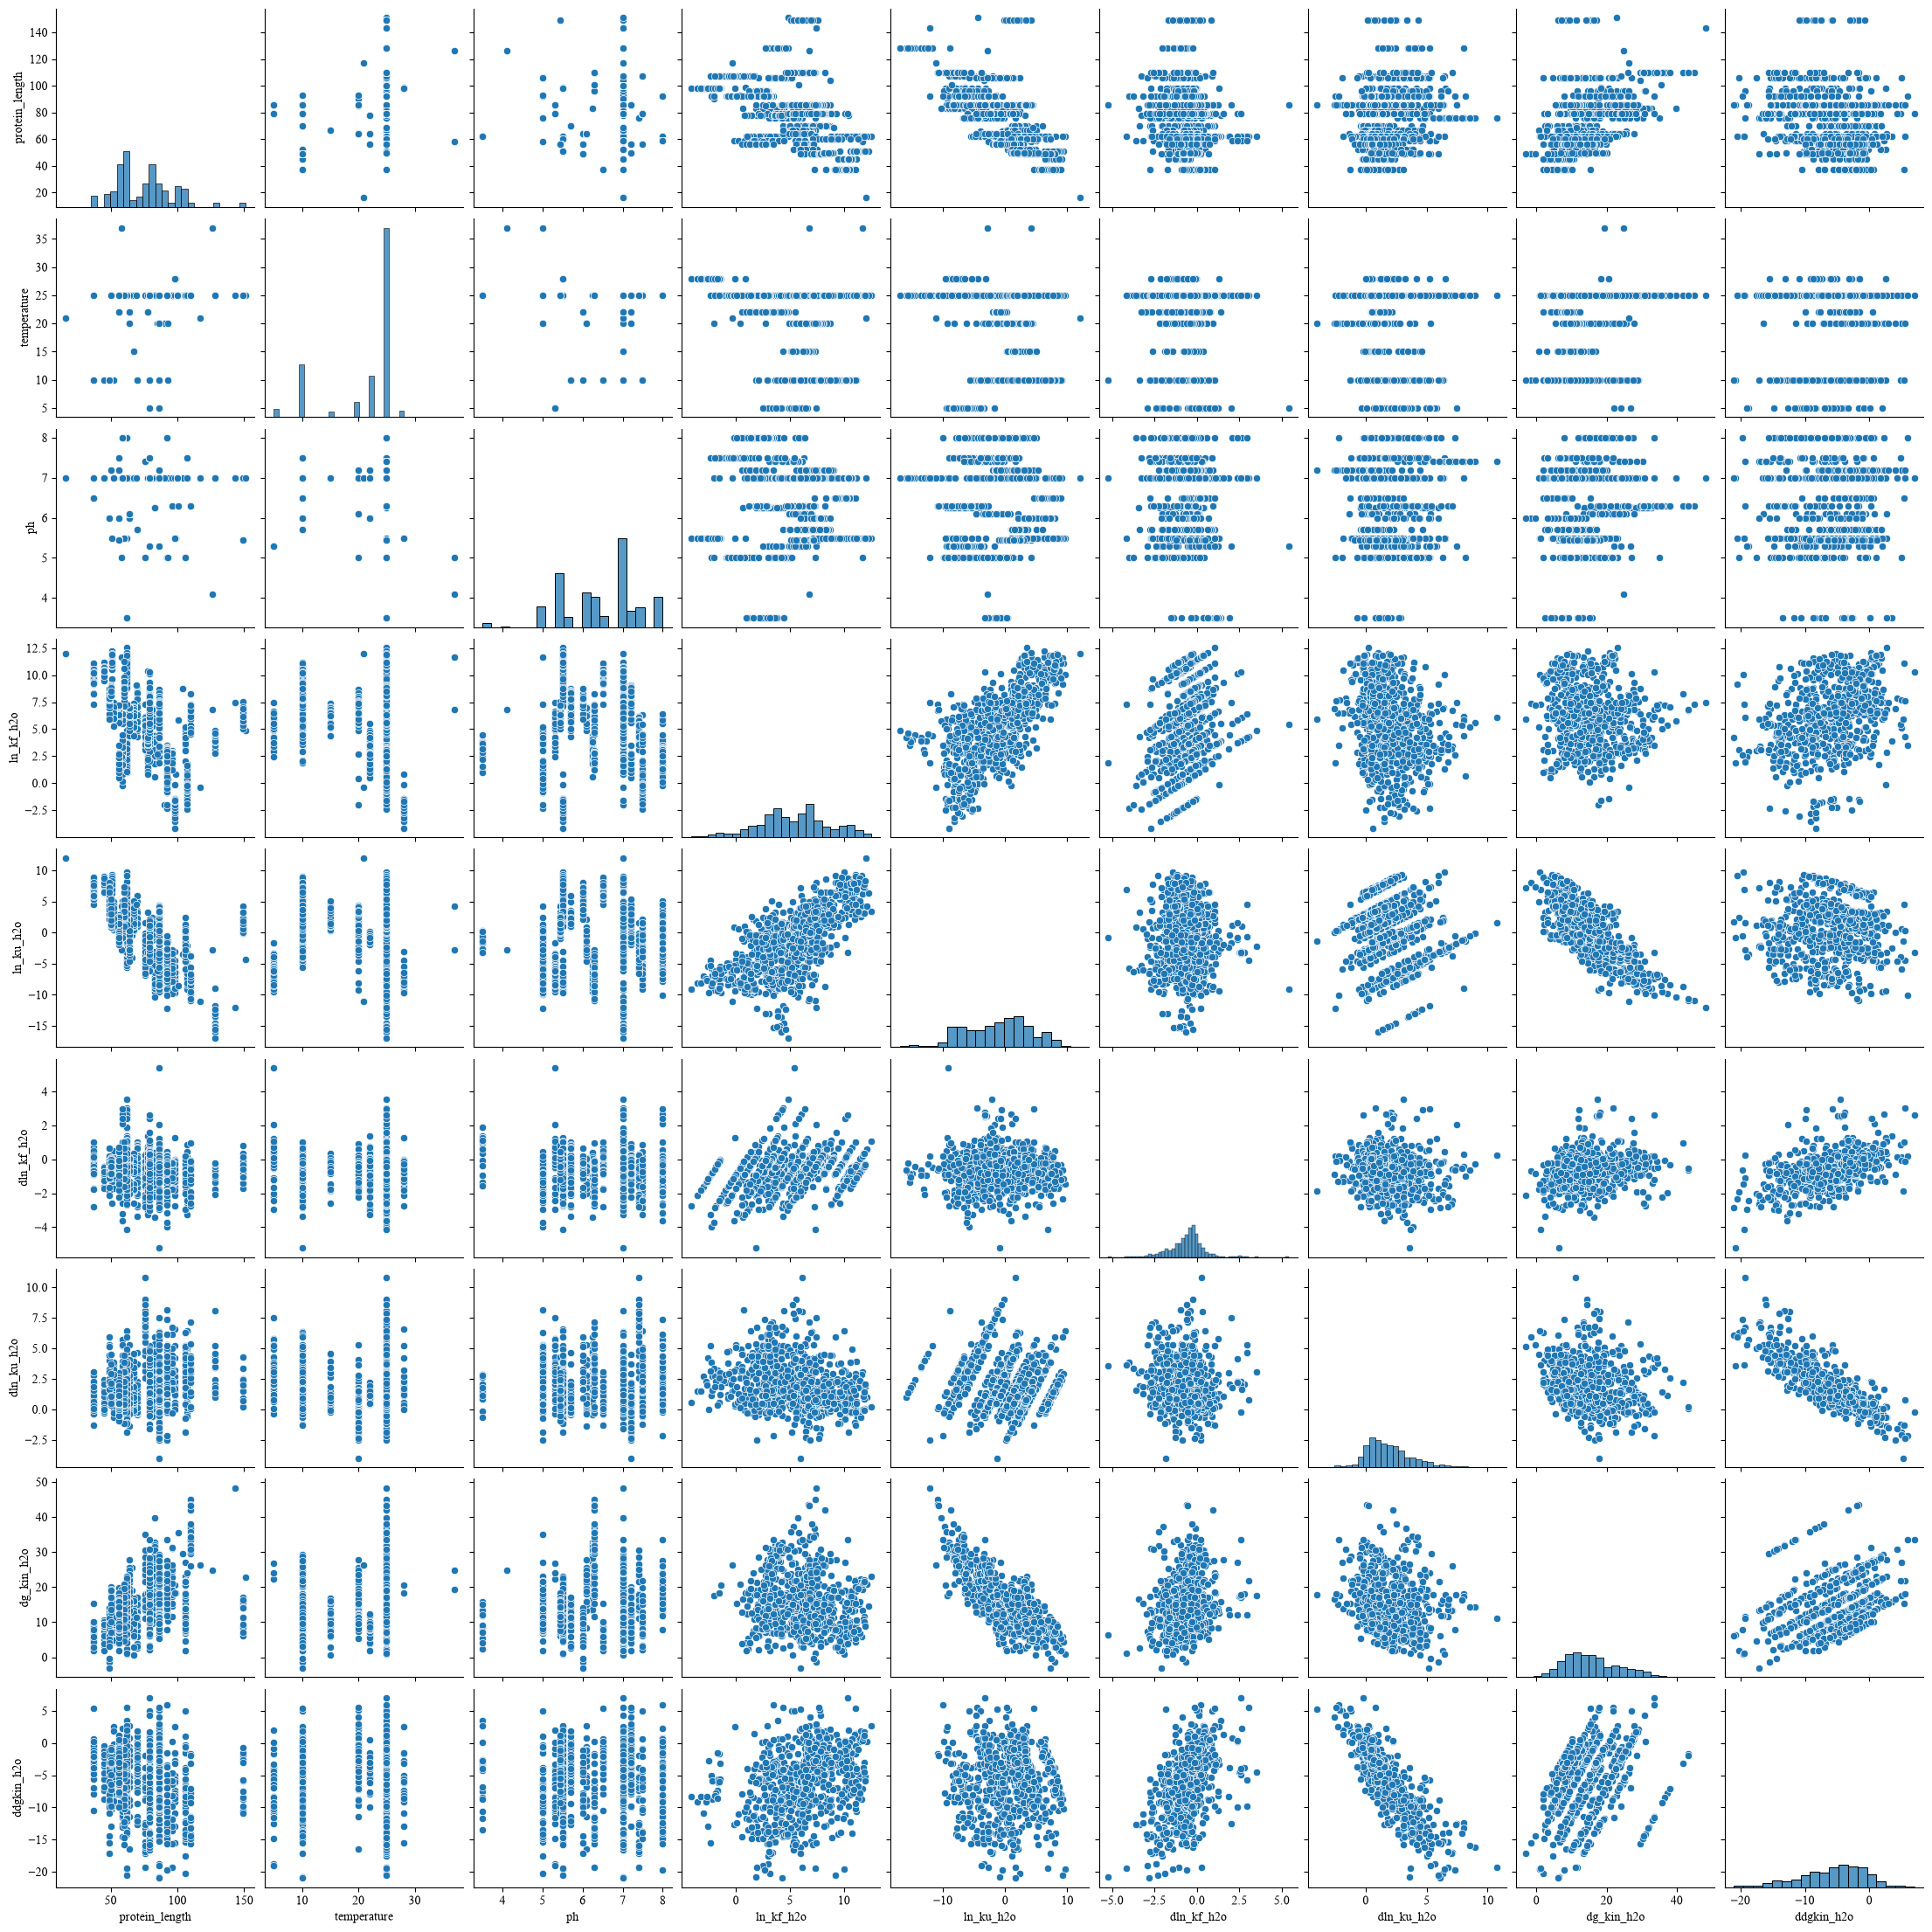

In [28]:
# Explore correlations
sns.pairplot(data = data_numeric, vars = column_names)
plt.show()

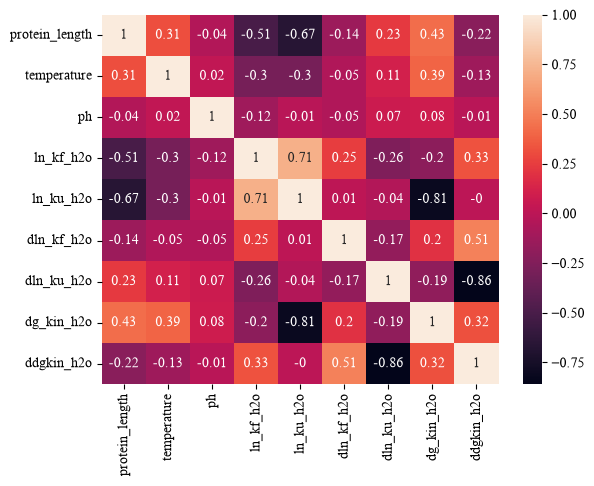

In [29]:
plt.Figure(figsize = (10,6))
sns.heatmap(round(data_numeric.corr(), 2), annot=True)
plt.show()

## Exploration of target variable

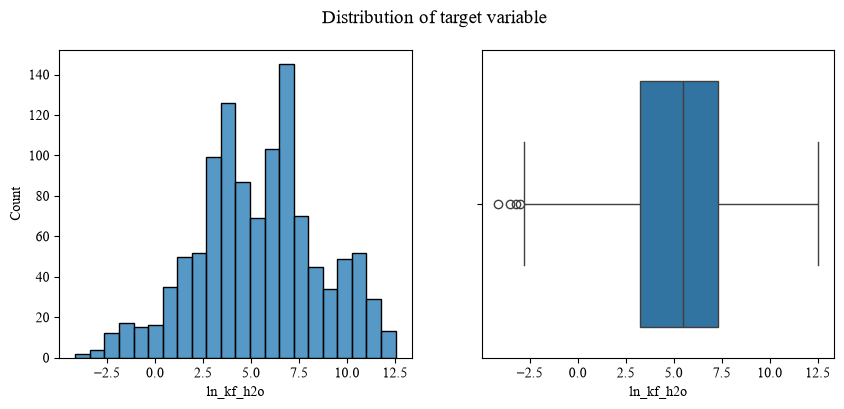

In [19]:
# Explore distribution of target variable
fig, ax = plt.subplots(1, 2, figsize = (10, 4))

sns.histplot(data = data, x = 'ln_kf_h2o', ax = ax[0])
sns.boxplot(data = data, x = 'ln_kf_h2o', ax = ax[1])
fig.suptitle('Distribution of target variable', fontsize = 14)
plt.show()

## Exploration of experimental conditions

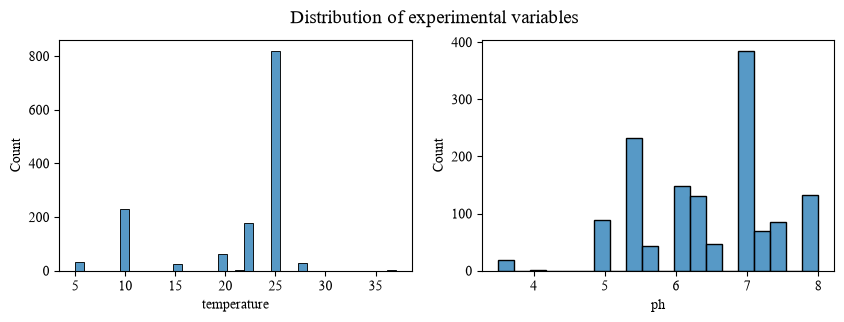

In [20]:
# Explore the applied methodologies
fig, ax = plt.subplots(1, 2, figsize = (10, 3))

sns.histplot(data = data, x = 'temperature', ax = ax[0])
sns.histplot(data = data, x = 'ph', ax = ax[1])
fig.suptitle('Distribution of experimental variables', fontsize = 14)
plt.show()

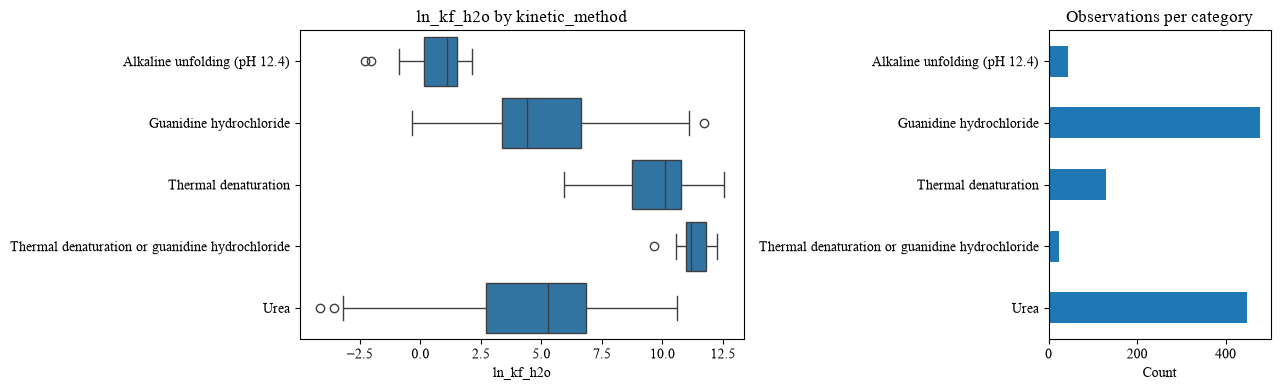

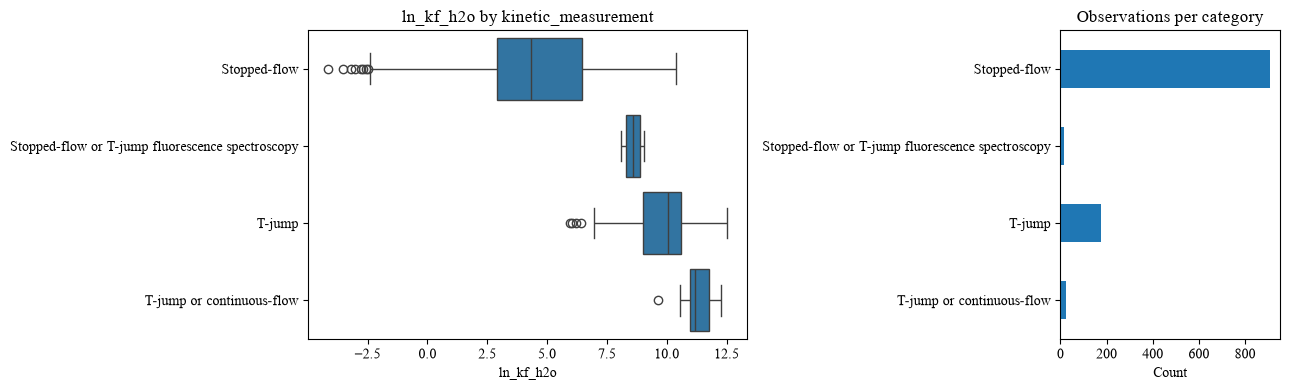

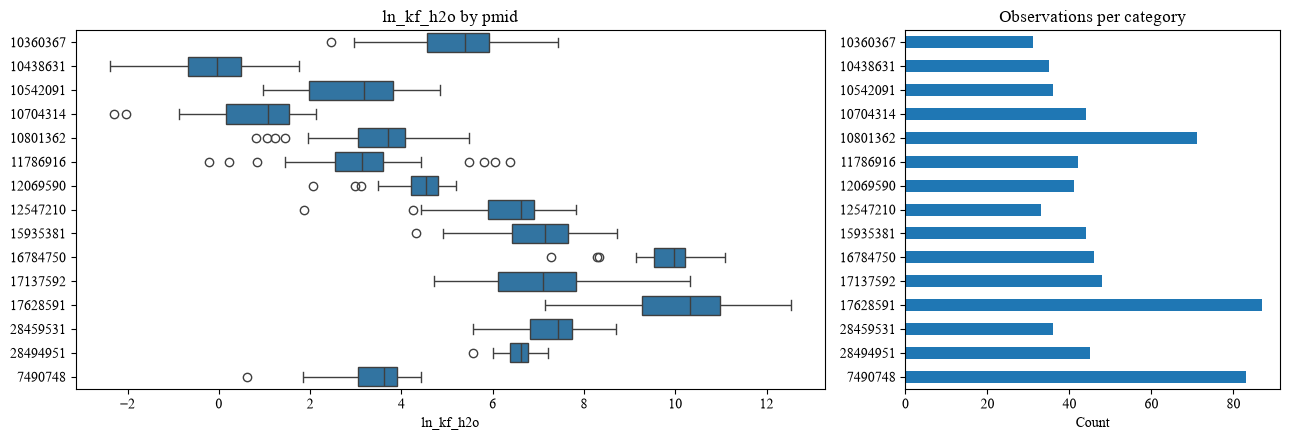

In [21]:
def plot_category_effect(data, category, target='ln_kf_h2o', min_count=10, top_n=15):
    plot_df = data[[category, target]].dropna().copy()

    # Keep sufficiently represented categories and limit very long plots.
    counts = plot_df[category].value_counts()
    categories = counts[counts >= min_count].head(top_n).index
    plot_df = plot_df[plot_df[category].isin(categories)]

    if plot_df.empty:
        print(f"No categories in {category!r} meet the minimum count.")
        return

    order = (
        plot_df.groupby(category)[target]
        .median()
        .sort_index()
        .index
    )

    fig, axes = plt.subplots(
        1, 2, figsize=(13, max(4, len(order) * 0.3)),
        gridspec_kw={"width_ratios": [2, 1]}
    )

    sns.boxplot(data=plot_df, x=target, y=category, order=order, ax=axes[0])
    axes[0].set_title(f"{target} by {category}")
    axes[0].set_ylabel("")

    count_order = plot_df[category].value_counts().sort_index(ascending = False)
    count_order.plot.barh(ax=axes[1])
    axes[1].set_title("Observations per category")
    axes[1].set_xlabel("Count")
    axes[1].set_ylabel("")

    fig.tight_layout()
    plt.show()


plot_category_effect(data, "kinetic_method")
plot_category_effect(data, "kinetic_measurement")
plot_category_effect(
    data,
    category="pmid",
    min_count=10,
    top_n=15,
)

In [22]:
# Explore proteins and mutations pr. experimental category
data_by_experiment = data.groupby(['kinetic_method', 'kinetic_measurement']).agg(
    unique_proteins = ('protein_id', 'nunique'),
    unique_mutations = ('mutation_id', 'nunique')
)
print('\n', data_by_experiment)


                                                                                                   unique_proteins  \
kinetic_method                                  kinetic_measurement                                                 
Alkaline unfolding (pH 12.4)                    Stopped-flow                                                    1   
Guanidine hydrochloride                         Manual mixing                                                   1   
                                                Stopped-flow                                                   26   
                                                Stopped-flow or T-jump fluorescence spectroscopy                1   
                                                T-jump                                                          1   
Thermal denaturation                            T-jump                                                          9   
Thermal denaturation or guanidine hydrochloride T-jump or cont

In [23]:
# For numeric variables: Explore coverage, spread, and association with target
for col in ["temperature", "ph"]:
    subset = data[[col, 'ln_kf_h2o']].dropna()

    print(f"\n{col}")
    print(f"Observations: {len(subset)}")
    print(f"Unique values: {subset[col].nunique()}")
    print(f"Spearman correlation: "
          f"{subset[col].corr(subset['ln_kf_h2o'], method='spearman'):.3f}")

# For categorical variables: Explore group-level variation
for col in ["kinetic_method", "kinetic_measurement", "pmid"]:
    summary = (
        data.dropna(subset=[col, 'ln_kf_h2o'])
        .groupby(col)['ln_kf_h2o']
        .agg(["count", "median", "mean", "std"])
        .sort_values("count", ascending=False)
    )

    print(f"\n{col}")
    print(summary.head(15).round(3))


temperature
Observations: 1124
Unique values: 9
Spearman correlation: -0.302

ph
Observations: 1124
Unique values: 17
Spearman correlation: -0.151

kinetic_method
                                                 count median       mean  \
kinetic_method                                                             
Guanidine hydrochloride                            478  4.395   5.095481   
Urea                                               449   5.28   4.572851   
Thermal denaturation                               130  10.11      9.727   
Alkaline unfolding (pH 12.4)                        44   1.08   0.725682   
Thermal denaturation or guanidine hydrochloride     23  11.16  11.259565   

                                                   std  
kinetic_method                                          
Guanidine hydrochloride                          2.332  
Urea                                             2.980  
Thermal denaturation                             1.460  
Alkaline unfolding

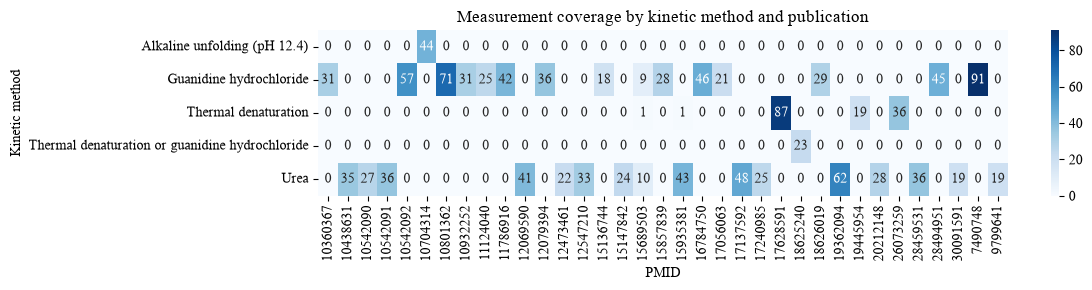

In [24]:
coverage = pd.crosstab(data["kinetic_method"], data["pmid"])

# Keep the most represented methods and publications for readability.
top_methods = data["kinetic_method"].value_counts().head(10).index
top_pmids = data["pmid"].value_counts().head(35).index

coverage = coverage.loc[
    coverage.index.intersection(top_methods),
    coverage.columns.intersection(top_pmids),
]

plt.figure(figsize=(12, 3))
sns.heatmap(coverage, annot=True, fmt="d", cmap="Blues")
plt.title("Measurement coverage by kinetic method and publication")
plt.xlabel("PMID")
plt.ylabel("Kinetic method")
plt.tight_layout()
plt.show()

## Exploration of protein coverage

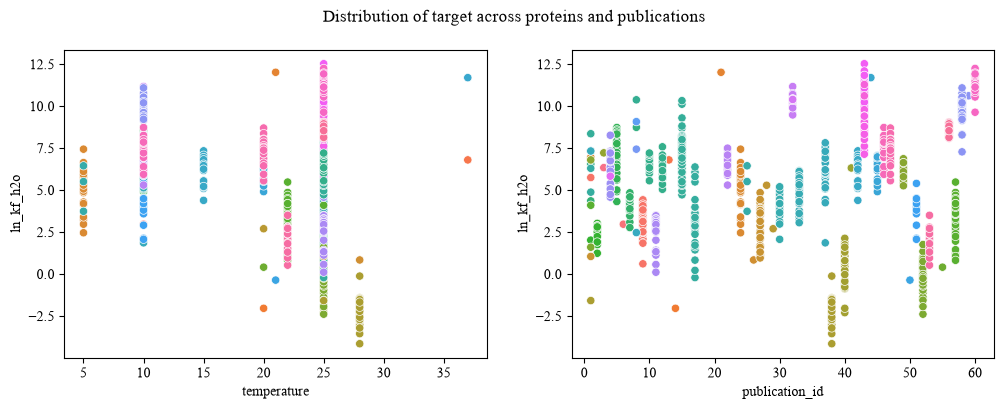

In [25]:
fig, ax = plt.subplots(1, 2, figsize = (12, 4))
sns.scatterplot(data = data, y = 'ln_kf_h2o', x = 'temperature', hue = 'protein_name', ax = ax[0], legend = False)
sns.scatterplot(data = data, y = 'ln_kf_h2o', x = 'publication_id', hue = 'protein_name', ax = ax[1], legend = False)
fig.suptitle('Distribution of target across proteins and publications')
plt.show()